Practice 6 (Version B)

In [26]:
import YData 


#### Download Practice 6 Jupyter Notebook ####  
#YData.download_practice_code(6)           # Without Answers. 
#YData.download_practice_code(6, True)     # With Answers. (Won't work until Friday eve.)



#### Download Data #### 
YData.download_data("apple_2025.csv")
YData.download_data("google_2025.csv")
YData.download.download_data("States_shapefile.geojson")
YData.download.download_data("state_demographics.csv")



#### Import Packages #### 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

The file `apple_2025.csv` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `google_2025.csv` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `States_shapefile.geojson` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `state_demographics.csv` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.


<br>
<br>
<br>

## Choropleth Maps - Population Over 64

Let's practice creating a choropleth map, this time of the percentage of people **over the age of 64** in each state. 

Data with the state boundaries and the demographic information are loaded below. Please do the following steps:

1. Join/merge the map data with the demographic data to create a new geoDataFrame called `state_map_demo`.
2. Create a new column in `state_map_demo` called `over_64_pct` that has the percentage of people over 64 (i.e., we are normalizing our choropleth map).
3. Plot the choropleth showing the percentage over 64, using a colormap other than `viridis` (e.g., `"plasma"` or `"YlOrRd"`). 
4. Which state has the highest percentage of people over 64? Which has the lowest?
5. **Challenge:** Create the same kind of map for the percentage of people **under 5**. Compare the two maps. Do the states with many older people tend to have few young children?

In [2]:
import geopandas as gpd

# The state boundaries data
state_map = gpd.read_file("States_shapefile.geojson")
print(state_map.crs)
state_map.head(3)

EPSG:4326


,FID,Program,State_Code,State_Name,Flowing_St,FID_1,geometry
0,1,PERMIT TRACKING,AL,ALABAMA,F,919,"POLYGON ((-85.07007 31.9807, -85.11515 31.9074..."
1,2,,AK,ALASKA,N,920,"MULTIPOLYGON (((-161.33379 58.73325, -161.3824..."
2,3,AZURITE,AZ,ARIZONA,F,921,"POLYGON ((-114.52063 33.02771, -114.55909 33.0..."


In [4]:
# The state demographic information 
state_demographics = pd.read_csv("state_demographics.csv")
state_demographics["State"] = state_demographics["State"].apply(str.upper)
state_demographics.head(3)

,State,under_5,over_64,bachelors_degree,total
0,ALABAMA,295811.997,741954.681,1095959.202,4849377
1,ALASKA,54518.168,69252.808,202601.300,736732
2,ARIZONA,430814.976,1070305.956,1810769.196,6731484


In [5]:
# Join/merge the state map with the state demographic data
state_merged = state_map.merge(
    state_demographics,
    left_on = "State_Name", 
    right_on = "State",
    how = "left"
)

In [8]:
# Add a new column called "over_64_pct" to "normalize your map"
state_merged["over_64_pct"] = 100 * state_merged["over_64"] / state_merged["total"]

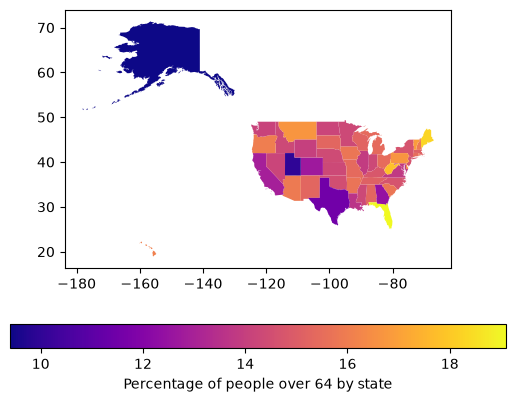

In [9]:
# Plot the choropleth map (use a colormap other than "viridis")
state_merged.plot(
    column = "over_64_pct",
    cmap = "plasma", legend = True,
    legend_kwds = {"label": "Percentage of people over 64 by state",
                   "orientation": "horizontal"});
    


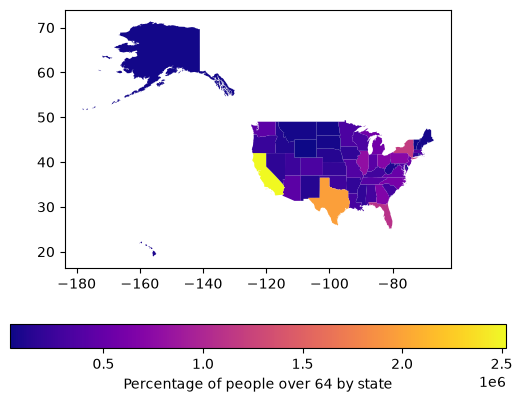

In [12]:
# Challenge: percentage under 5
state_merged.plot(
    column = "under_5", cmap = "plasma", legend = True,
    legend_kwds = {"label": "Percentage of people over 64 by state",
                   "orientation": "horizontal"}
);

<br>
<br>
<br>
<br>

# **For Loops in Python**

In [ ]:
# Generic Syntax. (Don't run this cell.)

for {iteration variable} in {iterable}:
           # do things

- Each for loop starts with the keyword `for`.

- The `iteration variable` is a variable that is declared only in the scope of the loop that is used to 'point' at the elements in the sequence.

- The `iterable` is a data structure that contains the sequence of elements we are going to perform tasks on, for example a list or a dictionary. 

<br>
<br>

### 1. Some Skills Builder Exercises

In [1]:
# 1.A 
# Loop over items in a list.
# Write a for loop to print every element of fruits in UPPER CASE (hint: the .upper() string method).

fruits = ["apple", "banana", "cherry", "date", "elderberry", "fig"]
for fruit in fruits:
    print(fruit.upper())


APPLE
BANANA
CHERRY
DATE
ELDERBERRY
FIG


In [3]:
# 1.B
# Loop over every third item in the list.
# Write a for loop to print every third element of fruits (starting with the first one).
for fruit in fruits[::3]:
    print(fruit)



apple
date


<br>

**Remark: When you call range, its value is not a list nor sequence of numbers. Loosely speaking, `range()` saves the instruction to iterate over a range of numbers. For example, `range(5)` defines the instruction to iterate over the first 5 numbers (starting at 0). That is why, used in a loop, it seems as if it is iterating over a list.**

In [5]:
# 1.C
# Loop over multiples of 4 (from 0 through 30) using the range() function.
# Write a for loop to print all the multiples of 4 from 0 through 30.
for i in range(0, 31, 4):
    print(i)


0
4
8
12
16
20
24
28


In [8]:
# 1.D
# Can you print the cube of every odd number from 1 to 9? 
for i in range(1, 10, 2):
    print(i**3)


1
27
125
343
729


In [11]:
# 1.E
# Create a list that has the cubes of the numbers from 1 through 8. 
# hint: the .append() method will be useful.
cube_list = []
for i in range(1, 9):
    cube_list.append(i**3)
    
print(cube_list)

[1, 8, 27, 64, 125, 216, 343, 512]


In [12]:
# 1.F
# Compute the product of the numbers from 1 through 6 (i.e., 6 factorial).
factorial = 1
for i in range(1, 7):
    factorial = factorial * i

factorial

720

<br>
<br>
<br>

### 2. The Enumerate function

**The `enumerate()` function adds a counter to each item in a list or other iterable. It turns the iterable into something we can loop through, where each item comes with its number/index (starting from 0 by default).**

In [15]:
# Example 2.A
# We can use enumerate(my_list) to get both values from a list and sequential index numbers.

colors = ["red", "green", "blue", "yellow"]

for index, color in enumerate(colors):
    print(str(index) + " -> " + color)

0 -> red
1 -> green
2 -> blue
3 -> yellow


In [8]:
# Example 2.B

words = ["Data", "science", "is", "fun"]

# Iterating over the list using enumerate to get both index and element.
for i, word in enumerate(words):
    print(f"Word number {i}: {word}")

Word number 0: Data
Word number 1: science
Word number 2: is
Word number 3: fun


<br>

**Question 2.C**: Explain (in about two lines or so) the Python code in Examples 2.A and 2.B, and what it accomplishes?

Answer: ....

In [16]:
# Question 2.D
# Use enumerate to print only the colors that are at an EVEN index (0, 2, ...), 
# along with their index.
for index, color in enumerate(colors):
    if index % 2 == 0:
        print(index, color) 

0 red
2 blue


<br>
<br>
<br>

### 3. The zip function

**The `zip()` function in Python is a built-in function that aggregates elements from multiple iterables (such as lists, tuples, or strings) and returns an iterator of tuples. Each tuple contains elements from the input iterables at the same corresponding position.** 

In [17]:
# Example 3.A

names  = ["Ana", "Ben", "Cy"]
scores = [90, 85, 77]

for name, score in zip(names, scores):
    print(name, "scored", score)

Ana scored 90
Ben scored 85
Cy scored 77


**Question 3.B**: Explain (in about two lines or so) the Python code in Example 3.A and what it accomplishes?

Answer: ....

In [19]:
# Question 3.C
# Use the zip function to print the same output as in Example 2.A above 
# (i.e., "0 -> red", "1 -> green", ...) without using enumerate.  

positions = [0, 1, 2, 3]
for index, color in zip(positions, colors):
    print(str(index), " -> ", color)

0  ->  red
1  ->  green
2  ->  blue
3  ->  yellow


In [23]:
# Question 3.D
# Use zip to print each person's score AFTER adding a 5 point bonus. 
# Then, build a list called `curved` containing the new scores.
curved = []
for name, score in zip(names, scores):
    new_score = score + 5
    curved.append(new_score)
    print(name, new_score)
    
curved

Ana 95
Ben 90
Cy 82


[95, 90, 82]

<br>
<br>
<br>

### 4. An Application: For loops

The code below extracts closing prices of Google and Apple stocks for Jan 01 through Sep 30. Please do the following:

1. Use a for loop to create a list called `apple_pct_change` that has the **daily percent change** of Apple's closing price, i.e., `100 * (today - yesterday) / yesterday`. (The first day has no "yesterday", so your list will have one fewer element than the data.)
2. Use a for loop and a conditional statement to count the number of days on which Google closed **higher** than Apple. Store the count in `google_higher`.

***There are a few ways to do this, so see if you can come up with a solution that works. Try to do this without using numpy, and once you have a solution, see if you can get the same result using numpy.***  

In [27]:
apple = pd.read_csv("apple_2025.csv")
google = pd.read_csv("google_2025.csv")

apple_close = apple["Close"].to_list()
google_close = google["Close"].to_list()

**1. First way to solve the problem: using `range()` and indexing.**

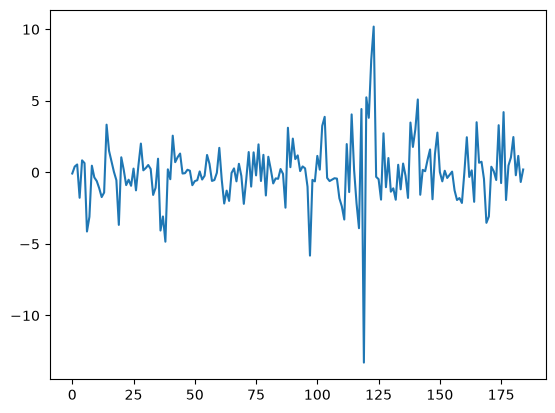

In [31]:
# Start with an empty list.
apple_pct_change = []

# Use a for loop to add the daily percent change to the list.
for i in range(1, len(apple_close)):
    dpc = 100 * (apple_close[i] - apple_close[i - 1]) / apple_close[i - 1]
    apple_pct_change.append(dpc)

# Plot daily percent changes.
plt.plot(apple_pct_change);

**2. Alternative solution using the zip function.**

In [ ]:
# Start with an empty list.
apple_pct_change2 = []

# Use a for loop (along with the zip function) to add the daily percent change to the list.



# Plot daily percent changes.




**3. Counting days with a loop, a conditional, and zip.**

In [ ]:
# Count the days on which Google closed higher than Apple.
google_higher = 0

**4. Solving the same problems with numpy.**

In [ ]:
# Same problems, using numpy.
apple_arr = np.array(apple_close)
google_arr = np.array(google_close)

<br>
<br>
<br>

##  5. Conditional Statements 

**Conditional statements allow you to execute particular pieces of code when certain conditions are met; that is, they execute a piece of code when a Boolean value is True. Let's explore!**

In [13]:
# Let us quickly take a look at the following conditional statement. 

temp = 72

if temp < 32:
    print("Freezing")
elif temp < 60:
    print("Cold")
elif temp < 80:
    print("Pleasant")
elif temp < 95:
    print("Hot")
else:
    print("Extreme heat")

Pleasant


**Question 5.A: Unlike above, the code in the cell below doesn't print *"Pleasant"*, why?**

Answer: ....

(Hint: Once one condition in an `if / elif / else` chain is `True`, what happens to the rest of the chain? Think about the order of the conditions.)

In [14]:
# 5.A 

temp = 72

if temp < 32:
    print("Freezing")
elif temp < 90:
    print("Cold")
elif temp < 80:
    print("Pleasant")
else: 
    print("Hot")

Cold


**Question 5.B: Unlike above, the code in the cell below prints *two* messages, why?**

Answer: ....

(Hint: Is `if temp < 80:` part of the same chain as the statements above it, or does it start a new one? Compare with an `elif`.)

In [15]:
# 5.B

temp = 50

if temp < 32:
    print("Freezing")
elif temp < 60:
    print("Cold")
if temp < 80:
    print("Pleasant")
else: 
    print("Hot")

Cold
Pleasant


<br>
<br>

In [16]:
# Let us now look at a conditional statement in a loop. 

temps = [10, 30, 50, 70, 90]

for temp in temps:
    
    print(temp)

    if temp < 32:
        print("Freezing")
    elif temp < 60:
        print("Cold")
    elif temp < 80:
        print("Pleasant")
    else:
        print("Hot")

10
Freezing
30
Freezing
50
Cold
70
Pleasant
90
Hot


**Question 5.C: Unlike above, the code in the cell below only prints the temperatures and a single `Hot`, instead of a label for each temperature. Why?**

Answer: ....

(Hint: Compare the indentation below with the indentation in the cell above. What value does `temp` have after the loop ends?)

In [17]:
for temp in temps:
    
    print(temp)

if temp < 32:
    print("Freezing")
elif temp < 60:
    print("Cold")
elif temp < 80:
    print("Pleasant")
else:
    print("Hot")

10
30
50
70
90
Hot


**Question 5.D**: Write a loop (with a conditional inside it) that goes through `temps` and counts how many of the temperatures are at least 50. 

In [ ]:
warm_count = 0

<br>
<br>
<br>

## 6. ***Take Home Exercise***

**Write a Python program to find all the numbers between $100$ and $200$ (both included) that are divisible by $3$ but are NOT multiples of $9$. Print them as a single comma-separated string. Recall `%` symbol in Python is called the Modulo Operator. It returns the remainder of dividing the left hand operand by right hand operand.**

*Bonus: also print how many such numbers there are.*

In [ ]:
# Create an empty list to store numbers that meet the given conditions.
new_list = []



# Iterate through numbers from 100 to 200 (inclusive)



# Join the numbers in the list with a comma and print the result



# Bonus: print how many such numbers there are